# FACED DE + SVM: Without Beta, corrected final fold
Binary cross-subject reproduction of released FACED analysis.


## Imports


In [1]:
import hashlib
import json
import pickle
import time
import warnings
from pathlib import Path
import joblib
import numpy as np
import scipy
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.io import loadmat
from scipy.stats import sem
from sklearn.svm import LinearSVC
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score,confusion_matrix
from threadpoolctl import threadpool_limits

def save_json(path,value):
    path.write_text(json.dumps(value,indent=2),encoding='utf-8')


## Config


In [2]:
band_indices = [0, 1, 2, 4]
normalization_mode = 'corrected'
environment = 'ubuntu_release'
experiment_root = Path('D:/EEG Experiment Artifacts/2026-11-02/reproduction')
dataset_root = Path('C:/FACED dataset')
seed = 7
n_jobs = 4
C_candidates = 10.0**np.arange(-5,1,.5)
run_training = True
band_names = ['Delta','Theta','Alpha','Beta','Gamma']
band_key = 'bands_'+''.join(map(str,band_indices))
run_name = band_key+'_'+normalization_mode+'_'+environment
run_dir = experiment_root/'runs'/run_name
run_dir.mkdir(parents=True,exist_ok=True)
selected_videos = np.r_[0:12,16:28]
labels = np.repeat(np.r_[np.zeros(12,dtype=int),np.ones(12,dtype=int)],30)
targets = np.tile(labels,(123,1))
settings = {'bands':band_indices,'band_names':[band_names[i] for i in band_indices],
 'seed':seed,'LinearSVC':{'dual':True,'max_iter':1000,'tol':1e-4,'penalty':'l2','loss':'squared_hinge'},
 'C_candidates':C_candidates.tolist(),'selection':'best held-out fold accuracy, literal official code; optimistic, not nested',
 'normalization_mode':normalization_mode,'RN_decay':.99,'RN_epsilon':1e-5,
 'LDS':{'V0':.01,'A':1,'T':.0001,'C':1,'sigma':1,'scope':'full canonical session'},
 'channel_norm':'per subject across complete 720-second session, includes unlabeled test EEG',
 'environment':environment,'versions':{'python':__import__('platform').python_version(),
 'numpy':np.__version__,'scipy':scipy.__version__,'sklearn':sklearn.__version__},
 'classes':2,'folds':10,'evaluation':'one-second accuracy, mean and SEM across 123 subjects'}
assert sklearn.__version__ == '1.1.2' and np.__version__ == '1.23.1' and scipy.__version__ == '1.9.0'
print('Execution host:',__import__('platform').platform(),'| release package set:',environment)
print('Run:',run_name,'| CPU workers:',n_jobs)
print('Bands:',settings['band_names'],'| normalization fold:',normalization_mode)
print('Original solver defaults: dual=True, max_iter=1000. Convergence warnings are retained.')
print('Reporting folds also select C, following the release. This is not an unbiased nested-CV estimate.')


Execution host: Windows-10-10.0.22621-SP0 | release package set: ubuntu_release
Run: bands_0124_corrected_ubuntu_release | CPU workers: 4
Bands: ['Delta', 'Theta', 'Alpha', 'Gamma'] | normalization fold: corrected
Original solver defaults: dual=True, max_iter=1000. Convergence warnings are retained.
Reporting folds also select C, following the release. This is not an unbiased nested-CV estimate.


## Data


In [3]:
source_dir = dataset_root/'Code/Code/Validation/Classification_validation/Svm_analysis'
input_paths = list(source_dir.glob('*.py')) + [dataset_root/'Code/Code/Readme.md',
    dataset_root/'Code/Code/Preprocessing/torch_win.yml',dataset_root/'Code/Code/Preprocessing/torch_ubuntu.yml',
    dataset_root/'Other Files/A Large Finer-grained Affective Computing EEG Dataset.pdf']
input_paths += list((dataset_root/'EEG_Features/DE').glob('*.pkl.pkl'))
input_paths += [dataset_root/'Data'/f'sub{s:03d}'/'After_remarks.mat' for s in range(123)]
input_paths += [dataset_root/'Code/Code/Validation/Classification_validation/subject_cross_vids_24_valid_10-folds.csv']
hashes = {str(path):hashlib.sha256(path.read_bytes()).hexdigest() for path in input_paths}
assert len(hashes)==258
hash_path = experiment_root/'input_hashes.json'
if hash_path.exists():
    assert json.loads(hash_path.read_text()) == hashes
else:
    save_json(hash_path,hashes)
cache = experiment_root/'cache'
cache.mkdir(exist_ok=True)
path = cache/'released_de.npy'
if not path.exists():
    de = np.stack([pickle.load(open(dataset_root/'EEG_Features/DE'/f'sub{s:03d}.pkl.pkl','rb'))[:,:30]
                   for s in range(123)])
    assert de.shape == (123,28,30,30,5)
    np.save(path,de)
    del de
released_de = np.load(path,mmap_mode='r')
assert released_de.shape == (123,28,30,30,5)
for sub in range(123):
    with (dataset_root/'EEG_Features/DE'/f'sub{sub:03d}.pkl.pkl').open('rb') as f:
        original_de = np.asarray(pickle.load(f))[:,:30]
    assert np.array_equal(released_de[sub],original_de), 'Cached DE differs from source files'
del original_de
# Official running_norm.py orders features as band then channel.
de = np.take(released_de,band_indices,axis=-1)
data = de.transpose(0,1,3,4,2).reshape(123,28,30,30*len(band_indices))[:,selected_videos]
data = np.ascontiguousarray(data.reshape(123,720,-1),dtype=np.float64)
del de
orders = []
for sub in range(123):
    remark = loadmat(dataset_root/'Data'/f'sub{sub:03d}'/'After_remarks.mat')['After_remark']
    order = [int(v.item())-1 for v in remark['vid'].ravel()]
    assert sorted(order) == list(range(28))
    orders.append([v if v<12 else v-4 for v in order if v<12 or v>=16])
orders = np.asarray(orders)
author_path = dataset_root/'Code/Code/Validation/Classification_validation/subject_cross_vids_24_valid_10-folds.csv'
author_scores = pd.read_csv(author_path,index_col=0).to_numpy().ravel()
assert author_scores.shape == (123,)
manifest = {'settings':settings,'input_hashes':hashes}
manifest_hash = hashlib.sha256(json.dumps(manifest,sort_keys=True).encode()).hexdigest()
config_path = run_dir/'config.json'
if config_path.exists():
    assert json.loads(config_path.read_text()) == manifest
else:
    save_json(config_path,manifest)
print('Data:',data.shape,'| author CSV mean/SEM (%):',100*author_scores.mean(),100*sem(author_scores))


Data: (123, 720, 120) | author CSV mean/SEM (%): 69.29878048780486 1.5152854293796658


## Running normalization and LDS


In [4]:
def normalize_lds(values,presentation,train):
    n,t,d = values.shape
    chronological = np.stack([values[s].reshape(24,30,d)[presentation[s]].reshape(t,d) for s in range(n)])
    # Literal release replaces NaN; no extra clipping or filtering is introduced.
    chronological[np.isnan(chronological)] = -30
    mean = chronological[train].mean(axis=1).mean(axis=0)
    var = chronological[train].var(axis=1).mean(axis=0)
    count = np.arange(1,t+1)[None,:,None]
    sums = np.cumsum(chronological,axis=1)
    running_mean = sums/count
    running_var = (np.cumsum(chronological**2,axis=1)-2*running_mean*sums)/count+running_mean**2
    decay = (.99**np.arange(t))[None,:,None]
    norm = (chronological-(decay*mean+(1-decay)*running_mean))/np.sqrt(decay*var+(1-decay)*running_var+1e-5)
    canonical = np.empty((n,24,30,d))
    for s in range(n):
        canonical[s,presentation[s]] = norm[s].reshape(24,30,d)
    canonical = canonical.reshape(n,t,d)
    smooth = np.empty_like(canonical)
    v = .01/(1+.01)
    smooth[:,0] = canonical.mean(axis=1)+v*(canonical[:,0]-canonical.mean(axis=1))
    variance = (1-v)*.01
    for second in range(1,t):
        prior = variance+.0001
        gain = prior/(prior+1)
        smooth[:,second] = smooth[:,second-1]+gain*(canonical[:,second]-smooth[:,second-1])
        variance = (1-gain)*prior
    # This normalization is separately applied to every subject in load_srt_de.
    return (smooth-smooth.mean(axis=1,keepdims=True))/smooth.std(axis=1,keepdims=True)

def fold_directory(fold):
    mode = normalization_mode if fold==9 else 'common'
    folder = experiment_root/'folds'/environment/band_key/f'fold_{fold:02d}_{mode}'
    folder.mkdir(parents=True,exist_ok=True)
    return folder

def fold_split(fold):
    held = np.arange(fold*12,(fold+1)*12 if fold<9 else 123)
    train = np.setdiff1d(np.arange(123),held)
    # The literal source excludes 108..118 for RN in the final fold, but the SVM tests 108..122.
    norm_held = np.arange(108,119) if fold==9 and normalization_mode=='legacy' else held
    norm_train = np.setdiff1d(np.arange(123),norm_held)
    return train,held,norm_train

def processed_features(folder, norm_train, fold_config):
    path = folder/'processed_features.npy'
    metadata_path = folder/'processed_features.json'
    config_hash = hashlib.sha256(json.dumps(fold_config,sort_keys=True).encode()).hexdigest()
    def file_hash(file):
        digest = hashlib.sha256()
        with file.open('rb') as stream:
            for block in iter(lambda:stream.read(8*1024*1024),b''):
                digest.update(block)
        return digest.hexdigest()
    if path.exists() and metadata_path.exists():
        metadata = json.loads(metadata_path.read_text())
        assert metadata['fold_config_sha256'] == config_hash
        assert file_hash(path) == metadata['sha256'], 'Processed cache checksum mismatch'
        z = np.load(path,mmap_mode='r')
        assert z.shape == data.shape and z.dtype == np.float64
        return z
    z = normalize_lds(data,orders,norm_train)
    assert z.dtype == np.float64 and np.isfinite(z).all()
    temporary = folder/'processed_features.pending.npy'
    np.save(temporary,z,allow_pickle=False)
    temporary.replace(path)
    save_json(metadata_path,{'sha256':file_hash(path),'fold_config_sha256':config_hash,
        'shape':list(z.shape),'dtype':str(z.dtype),'pipeline':['running normalization','LDS','per-subject session z-score'],
        'axis_order':['subject','canonical video then second','band then channel'],
        'subject_ids':list(range(123)),'video_ids_one_based':(selected_videos+1).tolist(),
        'seconds_per_video':30,'bands':settings['band_names'],'channels_one_based':list(range(1,31)),
        'labels_by_video':[0]*12+[1]*12,'presentation_order_zero_based':orders.tolist(),
        'normalization_training_subjects':norm_train.tolist(),'versions':settings['versions']})
    return np.load(path,mmap_mode='r')


## SVM


In [5]:
def fit_candidate(c,xtrain,ytrain,xtest,ytest):
    start = time.perf_counter()
    model = LinearSVC(C=float(c),random_state=seed,dual=True,max_iter=1000,tol=1e-4)
    with warnings.catch_warnings(record=True) as caught,threadpool_limits(limits=1):
        warnings.simplefilter('always',ConvergenceWarning)
        model.fit(xtrain,ytrain)
    predicted = model.predict(xtest)
    return model,{'C':float(c),'accuracy':float(np.mean(predicted==ytest)),
                  'seconds':time.perf_counter()-start,'n_iter':int(model.n_iter_),
                  'warnings':[str(w.message) for w in caught]}

def run_fold(fold):
    folder = fold_directory(fold)
    train,held,norm_train = fold_split(fold)
    fold_config = {'bands':band_indices,'seed':seed,'settings':{k:v for k,v in settings.items() if k!='normalization_mode'},
                   'train_subjects':train.tolist(),'test_subjects':held.tolist(),
                   'normalization_training_subjects':norm_train.tolist(),'input_hashes':hashes}
    config_path = folder/'config.json'
    if config_path.exists():
        assert json.loads(config_path.read_text()) == fold_config
    else:
        save_json(config_path,fold_config)
    z = processed_features(folder,norm_train,fold_config)
    if (folder/'metrics.json').exists():
        print('Restored completed/shared fold',fold,flush=True)
        return json.loads((folder/'metrics.json').read_text())
    start = time.perf_counter()
    xtrain,ytrain = z[train].reshape(-1,data.shape[-1]),targets[train].ravel()
    xtest,ytest = z[held].reshape(-1,data.shape[-1]),targets[held].ravel()
    temp = experiment_root/'parallel_cache'
    temp.mkdir(exist_ok=True)
    candidates = joblib.Parallel(n_jobs=n_jobs,backend='loky',temp_folder=str(temp),max_nbytes='1M')(
        joblib.delayed(fit_candidate)(c,xtrain,ytrain,xtest,ytest) for c in C_candidates)
    best_model,best = max(candidates,key=lambda item:item[1]['accuracy'])
    grid = [row for model,row in candidates]
    save_json(folder/'grid.json',grid)
    predicted = best_model.predict(xtest).reshape(len(held),720)
    decision = best_model.decision_function(xtest).reshape(len(held),720)
    np.savez_compressed(folder/'predictions.npz',predictions=predicted,labels=targets[held],decision=decision,subjects=held)
    joblib.dump(best_model,folder/'model.joblib')
    result = {'fold':fold,'subjects':held.tolist(),'best_C':best['C'],'accuracy':best['accuracy'],
              'selected_n_iter':best['n_iter'],'selected_warnings':best['warnings'],
              'candidate_warning_count':sum(len(r['warnings']) for r in grid),
              'normalization_overlap_with_test':np.intersect1d(norm_train,held).tolist(),
              'seconds':time.perf_counter()-start}
    save_json(folder/'metrics.json',result)
    print('FOLD COMPLETE',json.dumps(result),flush=True)
    return result

def summarize():
    predicted = np.full((123,720),-1,dtype=int)
    decision = np.full((123,720),np.nan)
    rows = []
    for fold in range(10):
        folder = fold_directory(fold)
        rows.append(json.loads((folder/'metrics.json').read_text()))
        saved = np.load(folder/'predictions.npz')
        predicted[saved['subjects']] = saved['predictions']
        decision[saved['subjects']] = saved['decision']
    assert (predicted>=0).all() and np.isfinite(decision).all()
    scores = (predicted==targets).mean(axis=1)
    np.savez_compressed(run_dir/'predictions.npz',predictions=predicted,labels=targets,decision=decision,subject_accuracy=scores)
    pd.DataFrame({'subject':np.arange(123),'accuracy':scores,'author_accuracy':author_scores,
                  'difference':scores-author_scores}).to_csv(run_dir/'subject_scores.csv',index=False)
    result = {'run_name':run_name,'manifest_hash':manifest_hash,'settings':settings,
              'accuracy':float(scores.mean()),'subject_sem':float(sem(scores)),
              'unweighted_fold_mean':float(np.mean([r['accuracy'] for r in rows])),
              'balanced_accuracy':float(balanced_accuracy_score(targets.ravel(),predicted.ravel())),
              'macro_f1':float(f1_score(targets.ravel(),predicted.ravel(),average='macro')),
              'author_accuracy':float(author_scores.mean()),'author_sem':float(sem(author_scores)),
              'absolute_mean_difference_pp':float(abs(scores.mean()-author_scores.mean())*100),
              'subject_MAE_pp':float(np.abs(scores-author_scores).mean()*100),
              'subject_RMSE_pp':float(np.sqrt(np.mean((scores-author_scores)**2))*100),
              'matching_subject_scores':int(np.isclose(scores,author_scores,atol=1e-12).sum()),
              'candidate_warning_count':sum(r['candidate_warning_count'] for r in rows),
              'selected_warning_count':sum(len(r['selected_warnings']) for r in rows),
              'folds':rows,'total_fold_seconds':sum(r['seconds'] for r in rows)}
    save_json(run_dir/'summary.json',result)
    return result


## Run


In [6]:
if run_training:
    for fold in range(10):
        run_fold(fold)
    results = summarize()
else:
    results = json.loads((run_dir/'summary.json').read_text())
print('COMPLETED',run_name)


Restored completed/shared fold 0
Restored completed/shared fold 1
Restored completed/shared fold 2
Restored completed/shared fold 3
Restored completed/shared fold 4
Restored completed/shared fold 5
Restored completed/shared fold 6
Restored completed/shared fold 7
Restored completed/shared fold 8
FOLD COMPLETE {"fold": 9, "subjects": [108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122], "best_C": 3.1622776601683795e-05, "accuracy": 0.6463888888888889, "selected_n_iter": 11, "selected_warnings": [], "candidate_warning_count": 4, "normalization_overlap_with_test": [], "seconds": 77.68489939999927}
COMPLETED bands_0124_corrected_ubuntu_release


## Results


Accuracy: 71.5763 +- 1.4809 % (subject SEM)
Author CSV: 69.2988 +- 1.5153 %
Absolute difference from author mean (pp): 2.2775519421860957
Per-subject MAE / RMSE (pp): 6.873306233062329 9.326884372972314
Exact matching subject accuracies: 3 / 123
Selected-model convergence warnings: 1
Reporting-fold C selection and full-session unlabeled test normalization match released behavior.
Numerical proximity alone does not establish an exact reproduction.


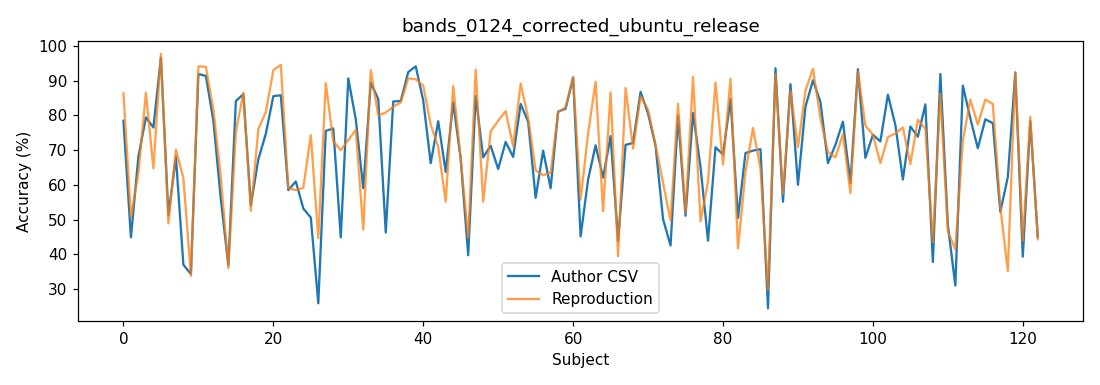

In [7]:
print('Accuracy: %.4f +- %.4f %% (subject SEM)' % (100*results['accuracy'],100*results['subject_sem']))
print('Author CSV: %.4f +- %.4f %%' % (100*results['author_accuracy'],100*results['author_sem']))
print('Absolute difference from author mean (pp):',results['absolute_mean_difference_pp'])
print('Per-subject MAE / RMSE (pp):',results['subject_MAE_pp'],results['subject_RMSE_pp'])
print('Exact matching subject accuracies:',results['matching_subject_scores'],'/ 123')
print('Selected-model convergence warnings:',results['selected_warning_count'])
print('Reporting-fold C selection and full-session unlabeled test normalization match released behavior.')
print('Numerical proximity alone does not establish an exact reproduction.')
subject_results = pd.read_csv(run_dir/'subject_scores.csv')
fig,ax = plt.subplots(figsize=(10,3.5))
ax.plot(subject_results['subject'],100*subject_results['author_accuracy'],label='Author CSV')
ax.plot(subject_results['subject'],100*subject_results['accuracy'],label='Reproduction',alpha=.75)
ax.set(xlabel='Subject',ylabel='Accuracy (%)',title=run_name)
ax.legend()
fig.tight_layout()
plt.show()
